# Kluebert Aspect-based Sentiment Analysis
## 단계별 검증 포함 전체 파이프라인



---
## STEP 0. 환경 설정

In [ ]:
!pip install transformers torch scikit-learn pandas numpy matplotlib seaborn tokenizers --quiet

import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, BertModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'디바이스: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print('환경 설정 완료')

디바이스: cuda
GPU: Tesla T4
환경 설정 완료


---
## STEP 1. CSV 로드 및 구조 확인

제일 먼저 데이터가 어떻게 생겼는지 파악해야 합니다.
특히 **한 리뷰(Index)가 여러 Aspect 행으로 쪼개진 구조**를 이해하는 게 핵심이에요.

In [ ]:
# ─────────────────────────────────────────
# 경로 설정
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/'

# ─────────────────────────────────────────

df = pd.read_csv(DATA_PATH + 'bert_train_skincare_12k.csv')

print('=' * 60)
print('[STEP 1] CSV 기본 정보')
print('=' * 60)
print(f'전체 행 수      : {len(df):,}행')
print(f'고유 리뷰 수    : {df["Index"].nunique():,}개  ← 이게 실제 리뷰 개수')
print(f'평균 Aspect 수  : {len(df) / df["Index"].nunique():.2f}개/리뷰')
print(f'컬럼            : {df.columns.tolist()}')
print()

print('[Label 분포]')
label_map = {0: '부정', 1: '중립', 2: '긍정'}
for label, count in df['Label'].value_counts().sort_index().items():
    bar = '█' * int(count / len(df) * 40)
    print(f'  {label} ({label_map[label]}): {count:,}건 ({count/len(df)*100:.1f}%)  {bar}')
print()

print('[Aspect 종류]')
print(df['Aspect'].value_counts().to_string())
print()

print('[결측치 확인]')
print(df.isnull().sum())

Mounted at /content/drive
[STEP 1] CSV 기본 정보
전체 행 수      : 38,603행
고유 리뷰 수    : 12,000개  ← 이게 실제 리뷰 개수
평균 Aspect 수  : 3.22개/리뷰
컬럼            : ['Index', 'RawText', 'Aspect', 'SentimentPolarity', 'ProductName', 'RDate', 'Label']

[Label 분포]
  0 (부정): 8,667건 (22.5%)  ████████
  1 (중립): 2,981건 (7.7%)  ███
  2 (긍정): 26,955건 (69.8%)  ███████████████████████████

[Aspect 종류]
Aspect
기능/효과       7213
보습력/수분감     7039
흡수력         3251
가격          3051
편의성/활용성     2381
윤기/피부(톤)    2376
제품구성        2153
향           1804
발림성         1745
자극성         1290
용량          1244
제형           993
피부타입         771
탄력           752
지속력          743
품질           457
용기           358
유통기한         313
성분           289
사용감          283
디자인           59
색상            27
밀착력/접착력        6
커버력            5

[결측치 확인]
Index                0
RawText              0
Aspect               0
SentimentPolarity    0
ProductName          0
RDate                0
Label                0
dtype: int64


In [ ]:
# 한 리뷰가 여러 행으로 쪼개진 구조를 눈으로 확인
print('=' * 60)
print('[STEP 1-2] 한 리뷰 = 여러 Aspect 행 구조 확인')
print('=' * 60)

# Aspect가 가장 많은 리뷰 하나 선택
most_aspects_idx = df.groupby('Index').size().idxmax()
sample = df[df['Index'] == most_aspects_idx][['Index','RawText','Aspect','SentimentPolarity','Label']]

print(f'리뷰 Index: {most_aspects_idx}')
print(f'이 리뷰의 RawText:')
print(f'  "{sample.iloc[0]["RawText"]}"')
print(f'\n→ 이 리뷰 하나가 {len(sample)}개 행으로 쪼개져 있음:')
print(sample[['Aspect','SentimentPolarity','Label']].to_string(index=False))
print()
print('⚠  이 구조 때문에 행 단위로 train/test 분할하면 같은 RawText가 양쪽에 들어갑니다!')

[STEP 1-2] 한 리뷰 = 여러 Aspect 행 구조 확인
리뷰 Index: 226806
이 리뷰의 RawText:
  "오늘 받아서 첨발라봅니다 우선 손등에 발라보니  화이트닝  되어 안바른 쪽과비교되게 하얗고 발림성도 부드럽고 촉촉하지만 끈적이지 않고 보송합니다. 얼굴에도 발라보니 역시 보송하고 화이트닝 되어 얼굴이 화사하게 살아나는것 같아요 꾸준히 발라보고  정말 기미가 색이 옅어지는지는 2주후에 확인해보겠습니다.참 단점이라곤  향이 좋지 않아요."

→ 이 리뷰 하나가 10개 행으로 쪼개져 있음:
  Aspect  SentimentPolarity  Label
   기능/효과                  1      2
윤기/피부(톤)                  1      2
     발림성                  1      2
 보습력/수분감                  1      2
     흡수력                  1      2
     흡수력                  1      2
     흡수력                  1      2
   기능/효과                  1      2
윤기/피부(톤)                  1      2
       향                 -1      0

⚠  이 구조 때문에 행 단위로 train/test 분할하면 같은 RawText가 양쪽에 들어갑니다!


---
## STEP 2. [이전 방식의 문제] 행 단위 분할 → 데이터 누수 확인

예전 코드가 왜 틀렸는지

In [ ]:
print('=' * 60)
print('[STEP 2] 이전 방식(행 단위 분할) 문제 증명')
print('=' * 60)

# ── 이전 방식 (버그 있는 코드) ──
old_train, old_temp = train_test_split(df, test_size=0.3, random_state=42, stratify=df['Label'])
old_valid, old_test = train_test_split(old_temp, test_size=0.5, random_state=42, stratify=old_temp['Label'])

old_train_ids = set(old_train['Index'])
old_test_ids  = set(old_test['Index'])
overlap       = old_train_ids & old_test_ids

print(f'[이전 방식] 행 단위 분할 결과:')
print(f'  Train: {len(old_train):,}행')
print(f'  Test : {len(old_test):,}행')
print()
print(f'[누수 측정]')
print(f'  Train 고유 리뷰 수     : {len(old_train_ids):,}개')
print(f'  Test  고유 리뷰 수     : {len(old_test_ids):,}개')
print(f'  ⚠  겹치는 리뷰 수     : {len(overlap):,}개  ({len(overlap)/len(old_test_ids)*100:.1f}% 누수!)')
print()

# 누수된 리뷰 예시 출력
leaked_idx = list(overlap)[:1][0]
print(f'[누수 예시] Index={leaked_idx} 리뷰가 train과 test에 동시에 존재:')
in_train = old_train[old_train['Index'] == leaked_idx][['Aspect','Label']]
in_test  = old_test[old_test['Index'] == leaked_idx][['Aspect','Label']]
print(f'  Train에 있는 행:')
print(in_train.to_string(index=False))
print(f'  Test에 있는 행:')
print(in_test.to_string(index=False))
print()
print('→ 모델이 train에서 이 텍스트를 이미 봤기 때문에 test에서 쉽게 맞힐 수 있음')
print('→ 진짜 일반화 성능이 아닌 "외운 것" 측정하게 됨')

[STEP 2] 이전 방식(행 단위 분할) 문제 증명
[이전 방식] 행 단위 분할 결과:
  Train: 27,022행
  Test : 5,791행

[누수 측정]
  Train 고유 리뷰 수     : 11,450개
  Test  고유 리뷰 수     : 4,742개
  ⚠  겹치는 리뷰 수     : 4,308개  (90.8% 누수!)

[누수 예시] Index=245760 리뷰가 train과 test에 동시에 존재:
  Train에 있는 행:
  Aspect  Label
윤기/피부(톤)      0
    제품구성      0
  Test에 있는 행:
Aspect  Label
 기능/효과      0
     향      0

→ 모델이 train에서 이 텍스트를 이미 봤기 때문에 test에서 쉽게 맞힐 수 있음
→ 진짜 일반화 성능이 아닌 "외운 것" 측정하게 됨


---
## STEP 3. [올바른 방식] Index 기준 분할

In [ ]:
print('=' * 60)
print('[STEP 3] 올바른 방식: Index 기준 분할')
print('=' * 60)

# 리뷰 Index를 먼저 분할한 다음 행을 가져옴
unique_ids = df['Index'].unique()
train_ids, temp_ids = train_test_split(unique_ids, test_size=0.3, random_state=42)
valid_ids, test_ids = train_test_split(temp_ids,   test_size=0.5, random_state=42)

train_df = df[df['Index'].isin(train_ids)].reset_index(drop=True)
valid_df = df[df['Index'].isin(valid_ids)].reset_index(drop=True)
test_df  = df[df['Index'].isin(test_ids)].reset_index(drop=True)

# 검증: 겹치는 리뷰가 0이어야 함
leakage = set(train_df['Index']) & set(test_df['Index'])

print(f'  Train: {len(train_df):,}행 ({train_df["Index"].nunique():,}개 리뷰)')
print(f'  Valid: {len(valid_df):,}행 ({valid_df["Index"].nunique():,}개 리뷰)')
print(f'  Test : {len(test_df):,}행  ({test_df["Index"].nunique():,}개 리뷰)')
print()
print(f'  누수 확인 (겹치는 리뷰): {len(leakage)}개', '✅ 완벽!' if len(leakage) == 0 else '❌ 아직 누수 있음')
print()

print('[각 split의 Label 분포]')
for name, split_df in [('Train', train_df), ('Valid', valid_df), ('Test', test_df)]:
    dist = split_df['Label'].value_counts(normalize=True).sort_index()
    dist_str = '  '.join([f'{label_map[k]}:{v*100:.1f}%' for k, v in dist.items()])
    print(f'  {name}: {dist_str}')

[STEP 3] 올바른 방식: Index 기준 분할
  Train: 27,038행 (8,400개 리뷰)
  Valid: 5,763행 (1,800개 리뷰)
  Test : 5,802행  (1,800개 리뷰)

  누수 확인 (겹치는 리뷰): 0개 ✅ 완벽!

[각 split의 Label 분포]
  Train: 부정:22.3%  중립:7.6%  긍정:70.0%
  Valid: 부정:21.5%  중립:7.6%  긍정:70.9%
  Test: 부정:24.0%  중립:8.3%  긍정:67.8%


---
## STEP 4. Tokenizer 로드 및 토큰화 결과 확인

토큰화가 어떻게 되는지, token_type_ids가 어떻게 생겼는지 눈으로 확인합니다.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained('klue/bert-base')

MAX_LEN = 192

print(f'Vocab 크기  : {len(tokenizer)}')
print(f'MAX_LEN     : {MAX_LEN}')
print(f'CLS token   : "{tokenizer.cls_token}" (id={tokenizer.cls_token_id})')
print(f'SEP token   : "{tokenizer.sep_token}" (id={tokenizer.sep_token_id})')
print(f'PAD token   : "{tokenizer.pad_token}" (id={tokenizer.pad_token_id})')
print(f'padding_side: {tokenizer.padding_side}')  # right여야 정상

config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Vocab 크기  : 32000
MAX_LEN     : 192
CLS token   : "[CLS]" (id=2)
SEP token   : "[SEP]" (id=3)
PAD token   : "[PAD]" (id=0)
padding_side: right


In [ ]:
sample_text   = '가격대비 좋아요. 향기는 좋은데, 향이 오래 가지 않아 아쉽습니다.'
sample_aspect = '향'

enc = tokenizer(
    sample_text,
    sample_aspect,
    add_special_tokens=True,
    max_length=MAX_LEN,
    padding='max_length',
    truncation=True,
    return_attention_mask=True,
    return_token_type_ids=True,
    return_tensors='pt'
)

input_ids      = enc['input_ids'][0].tolist()
attention_mask = enc['attention_mask'][0].tolist()
token_type_ids = enc['token_type_ids'][0].tolist()
tokens         = tokenizer.convert_ids_to_tokens(input_ids)

real_len = sum(attention_mask)

print(f'입력 text   : "{sample_text}"')
print(f'입력 aspect : "{sample_aspect}"')
print(f'실제 토큰 수: {real_len}개  (패딩 포함 전체: {MAX_LEN})')
print()
print('[실제 토큰 / token_type_ids]  (패딩 제외)')
print(f'{"idx":>4}  {"token":>15}  {"type_id":>7}  의미')
print('-' * 50)

for i in range(real_len):
    tok = tokens[i]
    tid = token_type_ids[i]
    meaning = ''
    if tok == tokenizer.cls_token:
        meaning = '← 문장 시작'
    elif tok == tokenizer.sep_token and tid == 0:
        meaning = '← text / aspect 구분'
    elif tok == tokenizer.sep_token and tid == 1:
        meaning = '← 문장 끝'
    type_label = 'text' if tid == 0 else 'aspect'
    print(f'{i:>4}  {tok:>15}  {tid:>7} ({type_label})  {meaning}')

입력 text   : "가격대비 좋아요. 향기는 좋은데, 향이 오래 가지 않아 아쉽습니다."
입력 aspect : "향"
실제 토큰 수: 25개  (패딩 포함 전체: 192)

[실제 토큰 / token_type_ids]  (패딩 제외)
 idx            token  type_id  의미
--------------------------------------------------
   0            [CLS]        0 (text)  ← 문장 시작
   1              가격대        0 (text)  
   2              ##비        0 (text)  
   3               좋아        0 (text)  
   4              ##요        0 (text)  
   5                .        0 (text)  
   6               향기        0 (text)  
   7              ##는        0 (text)  
   8                좋        0 (text)  
   9              ##은        0 (text)  
  10              ##데        0 (text)  
  11                ,        0 (text)  
  12                향        0 (text)  
  13              ##이        0 (text)  
  14               오래        0 (text)  
  15               가지        0 (text)  
  16                않        0 (text)  
  17              ##아        0 (text)  
  18               아쉽        0 (text)  
  19          

In [ ]:
input_ids      = enc['input_ids'][0].tolist()
attention_mask = enc['attention_mask'][0].tolist()
token_type_ids = enc['token_type_ids'][0].tolist()
tokens         = tokenizer.convert_ids_to_tokens(input_ids)

real_len = sum(attention_mask)  # 패딩 제외 실제 토큰 수
# KLUE-BERT는 right padding → 실제 토큰이 앞쪽에 있음
# 그냥 0부터 real_len까지 슬라이싱하면 됨

print(f'입력 text   : "{sample_text}"')
print(f'입력 aspect : "{sample_aspect}"')
print(f'실제 토큰 수: {real_len}개  (패딩 포함 전체: {MAX_LEN})')
print()
print('[실제 토큰 / token_type_ids]  (패딩 제외)')
print(f'{"idx":>4}  {"token":>15}  {"type_id":>7}  의미')
print('-' * 50)

for i in range(real_len):
    tok = tokens[i]
    tid = token_type_ids[i]
    meaning = ''
    if tok == tokenizer.cls_token:
        meaning = '← 문장 시작'
    elif tok == tokenizer.sep_token and tid == 0:
        meaning = '← text / aspect 구분'
    elif tok == tokenizer.sep_token and tid == 1:
        meaning = '← 문장 끝'
    type_label = 'text' if tid == 0 else 'aspect'
    print(f'{i:>4}  {tok:>15}  {tid:>7} ({type_label})  {meaning}')

print()
print('✅ [CLS] text토큰들 [SEP] aspect토큰들 [SEP] PAD... 순서로 나오면 정상입니다.')

입력 text   : "가격대비 좋아요. 향기는 좋은데, 향이 오래 가지 않아 아쉽습니다."
입력 aspect : "향"
실제 토큰 수: 25개  (패딩 포함 전체: 192)

[실제 토큰 / token_type_ids]  (패딩 제외)
 idx            token  type_id  의미
--------------------------------------------------
   0            [CLS]        0 (text)  ← 문장 시작
   1              가격대        0 (text)  
   2              ##비        0 (text)  
   3               좋아        0 (text)  
   4              ##요        0 (text)  
   5                .        0 (text)  
   6               향기        0 (text)  
   7              ##는        0 (text)  
   8                좋        0 (text)  
   9              ##은        0 (text)  
  10              ##데        0 (text)  
  11                ,        0 (text)  
  12                향        0 (text)  
  13              ##이        0 (text)  
  14               오래        0 (text)  
  15               가지        0 (text)  
  16                않        0 (text)  
  17              ##아        0 (text)  
  18               아쉽        0 (text)  
  19          

In [ ]:
# 실제 리뷰 여러 개의 토큰 수 분포 확인
print('=' * 60)
print('[STEP 4-3] 리뷰 토큰 수 분포 (샘플 500개)')
print('=' * 60)

sample_500 = df.sample(500, random_state=42)
token_lengths = []
for _, row in sample_500.iterrows():
    enc = tokenizer(str(row['RawText']), str(row['Aspect']),
                    add_special_tokens=True, truncation=False)
    token_lengths.append(len(enc['input_ids']))

token_lengths = np.array(token_lengths)
print(f'  평균  : {token_lengths.mean():.1f} 토큰')
print(f'  중앙값: {np.median(token_lengths):.0f} 토큰')
print(f'  75%   : {np.percentile(token_lengths, 75):.0f} 토큰')
print(f'  90%   : {np.percentile(token_lengths, 90):.0f} 토큰')
print(f'  95%   : {np.percentile(token_lengths, 95):.0f} 토큰')
print(f'  최대  : {token_lengths.max()} 토큰')
print()
over_128 = (token_lengths > 128).sum()
over_192 = (token_lengths > 192).sum()
print(f'  MAX_LEN=128로 잘리는 비율: {over_128/len(token_lengths)*100:.1f}%')
print(f'  MAX_LEN=192로 잘리는 비율: {over_192/len(token_lengths)*100:.1f}%')
print(f'  → MAX_LEN=192가 적절합니다.')

[STEP 4-3] 리뷰 토큰 수 분포 (샘플 500개)
  평균  : 58.6 토큰
  중앙값: 53 토큰
  75%   : 72 토큰
  90%   : 89 토큰
  95%   : 107 토큰
  최대  : 264 토큰

  MAX_LEN=128로 잘리는 비율: 2.4%
  MAX_LEN=192로 잘리는 비율: 0.6%
  → MAX_LEN=192가 적절합니다.


---
## STEP 5. Dataset 클래스 (token_type_ids 포함, 올바른 버전)

In [ ]:
class ReviewDataset(Dataset):
    """
    변경사항:
      1) token_type_ids를 반환값에 추가
      2) 나머지 구조 동일
    """
    def __init__(self, texts, aspects, labels, tokenizer, max_len):
        self.texts     = texts
        self.aspects   = aspects
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text   = str(self.texts[idx])
        aspect = str(self.aspects[idx])
        label  = int(self.labels[idx])
# tokenizer 호출 부분에 return_token_type_ids=True 추가
        encoding = self.tokenizer(
            text,
            aspect,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_token_type_ids=True,   # ← 추가
            return_tensors='pt'
        )

        return {
            'input_ids'      : encoding['input_ids'].flatten(),
            'attention_mask' : encoding['attention_mask'].flatten(),
            'token_type_ids' : encoding['token_type_ids'].flatten(),  # ← 추가
            'label'          : torch.tensor(label, dtype=torch.long)
        }


# Dataset 생성
train_dataset = ReviewDataset(train_df['RawText'].values, train_df['Aspect'].values, train_df['Label'].values, tokenizer, MAX_LEN)
valid_dataset = ReviewDataset(valid_df['RawText'].values, valid_df['Aspect'].values, valid_df['Label'].values, tokenizer, MAX_LEN)
test_dataset  = ReviewDataset(test_df['RawText'].values,  test_df['Aspect'].values,  test_df['Label'].values,  tokenizer, MAX_LEN)

print('=' * 60)
print('[STEP 5] Dataset 샘플 검증')
print('=' * 60)

# 실제 샘플 하나 꺼내서 key/shape 확인
sample_item = train_dataset[0]
print('[train_dataset[0] 반환값]')
for key, val in sample_item.items():
    print(f'  {key:20s}: shape={val.shape}, dtype={val.dtype}')

print()
print('[token_type_ids 확인]  (실제 토큰 부분만)')
ids   = sample_item['input_ids'].tolist()
ttids = sample_item['token_type_ids'].tolist()
masks = sample_item['attention_mask'].tolist()
real  = sum(masks)
toks  = tokenizer.convert_ids_to_tokens(ids[:real])

text_part   = [t for t, tt in zip(toks, ttids[:real]) if tt == 0 and t not in [tokenizer.cls_token, tokenizer.sep_token]]
aspect_part = [t for t, tt in zip(toks, ttids[:real]) if tt == 1 and t != tokenizer.sep_token]
print(f'  text 토큰   (type_id=0): {text_part}')
print(f'  aspect 토큰 (type_id=1): {aspect_part}')
print()
print('✅ token_type_ids가 올바르게 구분됩니다.')

[STEP 5] Dataset 샘플 검증
[train_dataset[0] 반환값]
  input_ids           : shape=torch.Size([192]), dtype=torch.int64
  attention_mask      : shape=torch.Size([192]), dtype=torch.int64
  token_type_ids      : shape=torch.Size([192]), dtype=torch.int64
  label               : shape=torch.Size([]), dtype=torch.int64

[token_type_ids 확인]  (실제 토큰 부분만)
  text 토큰   (type_id=0): ['식구', '##가', '많', '##은', '##데', '얼굴', '##에도', '바르', '##고', '몸', '##에도', '바르', '##라고', '한꺼번에', '여러', '##개', '샀', '##습', '##니다', '.', '가격', '##이', '너무', '저렴', '##해', '아낌없이', '사용', '##할', '수', '있', '##고', '품질', '##도', '그럭저럭', '괜찮', '##습', '##니다', '.', '바디', '##로', '##션', '##으로', '##도', '좋', '##습', '##니다', '.']
  aspect 토큰 (type_id=1): ['가격']

✅ token_type_ids가 올바르게 구분됩니다.


In [ ]:
# DataLoader 생성 및 배치 확인
BATCH_SIZE = 16

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# 배치 하나 꺼내서 shape 확인
sample_batch = next(iter(train_loader))

print('=' * 60)
print('[STEP 5-2] DataLoader 배치 shape 확인')
print('=' * 60)
for key, val in sample_batch.items():
    print(f'  {key:20s}: {val.shape}')

print()
print(f'  Train 배치 수: {len(train_loader)}')
print(f'  Valid 배치 수: {len(valid_loader)}')
print(f'  Test  배치 수: {len(test_loader)}')

[STEP 5-2] DataLoader 배치 shape 확인
  input_ids           : torch.Size([16, 192])
  attention_mask      : torch.Size([16, 192])
  token_type_ids      : torch.Size([16, 192])
  label               : torch.Size([16])

  Train 배치 수: 1690
  Valid 배치 수: 361
  Test  배치 수: 363


---
## STEP 6. 클래스 불균형 확인 및 class_weight 계산

In [ ]:
print('=' * 60)
print('[STEP 6] 클래스 불균형 → class_weight 계산')
print('=' * 60)

print('[Train Label 분포]')
for label, count in train_df['Label'].value_counts().sort_index().items():
    bar = '█' * int(count / len(train_df) * 40)
    print(f'  {label} ({label_map[label]}): {count:,}건 ({count/len(train_df)*100:.1f}%)  {bar}')

print()
print('⚠  긍정이 70%라 class_weight 없으면 모델이 긍정만 찍어도 70% 정확도가 나옵니다.')
print()

# class_weight 계산
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=train_df['Label'].values
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

print('[계산된 class_weight]')
for i, w in enumerate(class_weights):
    print(f'  {i} ({label_map[i]}): {w:.4f}  → 학습 시 이 배율로 loss 반영')

print()
print('→ 중립(8%)에 가장 높은 weight가 붙어서 균형을 맞춥니다.')

[STEP 6] 클래스 불균형 → class_weight 계산
[Train Label 분포]
  0 (부정): 6,036건 (22.3%)  ████████
  1 (중립): 2,065건 (7.6%)  ███
  2 (긍정): 18,937건 (70.0%)  ████████████████████████████

⚠  긍정이 70%라 class_weight 없으면 모델이 긍정만 찍어도 70% 정확도가 나옵니다.

[계산된 class_weight]
  0 (부정): 1.4932  → 학습 시 이 배율로 loss 반영
  1 (중립): 4.3645  → 학습 시 이 배율로 loss 반영
  2 (긍정): 0.4759  → 학습 시 이 배율로 loss 반영

→ 중립(8%)에 가장 높은 weight가 붙어서 균형을 맞춥니다.


---
## STEP 7. 모델 정의 (token_type_ids 포함, 올바른 버전)

In [ ]:
class KLUEClassifier(nn.Module):
    """
    변경사항:
      1) forward 인자에 token_type_ids 추가
      2) BertModel 호출 시 token_type_ids 전달
    """
    def __init__(self, num_classes=3, dropout=0.3):
        super().__init__()
        self.bert = BertModel.from_pretrained('klue/bert-base')

        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask, token_type_ids):  # ← 인자 추가
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids   # ← BertModel에 전달
        )
        pooled = self.dropout(outputs.pooler_output)
        return self.classifier(pooled)


model = KLUEClassifier(num_classes=3).to(device)

print('=' * 60)
print('[STEP 7] 모델 구조 확인')
print('=' * 60)
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'전체 파라미터    : {total_params:,}')
print(f'학습 가능 파라미터: {trainable_params:,}')
print()
print('[forward() 인자 확인]')
import inspect
sig = inspect.signature(model.forward)
print(f'  {sig}')
print()
print('✅ token_type_ids가 forward에 포함되어 있습니다.')

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: klue/bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[STEP 7] 모델 구조 확인
전체 파라미터    : 110,619,651
학습 가능 파라미터: 110,619,651

[forward() 인자 확인]
  (input_ids, attention_mask, token_type_ids)

✅ token_type_ids가 forward에 포함되어 있습니다.


In [ ]:
# 모델에 실제 배치를 넣어서 forward pass 확인
print('=' * 60)
print('[STEP 7-2] 더미 forward pass 확인 (실제 배치 1개)')
print('=' * 60)

model.eval()
with torch.no_grad():
    test_batch = {k: v.to(device) for k, v in sample_batch.items()}
    logits = model(
        input_ids=test_batch['input_ids'],
        attention_mask=test_batch['attention_mask'],
        token_type_ids=test_batch['token_type_ids']   # ← 여기도 반드시!
    )

print(f'입력 input_ids shape      : {test_batch["input_ids"].shape}')
print(f'입력 token_type_ids shape : {test_batch["token_type_ids"].shape}')
print(f'출력 logits shape         : {logits.shape}  → (배치크기=16, 클래스=3)')
print(f'첫 번째 샘플 logits       : {logits[0].tolist()}')
preds = torch.argmax(logits, dim=1)
print(f'첫 번째 배치 예측         : {preds.tolist()}')
print()
print('✅ forward pass 정상 동작 확인!')
model.train()

[STEP 7-2] 더미 forward pass 확인 (실제 배치 1개)
입력 input_ids shape      : torch.Size([16, 192])
입력 token_type_ids shape : torch.Size([16, 192])
출력 logits shape         : torch.Size([16, 3])  → (배치크기=16, 클래스=3)
첫 번째 샘플 logits       : [0.10056177526712418, -0.35939446091651917, -0.5783042907714844]
첫 번째 배치 예측         : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 1, 0]

✅ forward pass 정상 동작 확인!


KoBERTClassifier(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_

---
## STEP 8. 학습 설정 및 학습 루프

In [ ]:
EPOCHS    = 5
LR        = 2e-5
WARMUP    = 0.1   # 전체 스텝의 10%를 warmup

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)  # ← class_weight 적용

total_steps   = len(train_loader) * EPOCHS
warmup_steps  = int(total_steps * WARMUP)
scheduler     = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

print('=' * 60)
print('[STEP 8] 학습 설정 확인')
print('=' * 60)
print(f'Epochs          : {EPOCHS}')
print(f'Learning rate   : {LR}')
print(f'Total steps     : {total_steps:,}')
print(f'Warmup steps    : {warmup_steps:,}')
print(f'Loss function   : CrossEntropyLoss (class_weight={[f"{w:.3f}" for w in class_weights]})')
print(f'  → 긍정에는 낮은 weight, 중립에는 높은 weight 적용')

[STEP 8] 학습 설정 확인
Epochs          : 5
Learning rate   : 2e-05
Total steps     : 8,450
Warmup steps    : 845
Loss function   : CrossEntropyLoss (class_weight=['1.493', '4.364', '0.476'])
  → 긍정에는 낮은 weight, 중립에는 높은 weight 적용


In [ ]:
def train_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for batch in tqdm(loader, desc='Train', leave=False):
        optimizer.zero_grad()

        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)  # ← 추가
        labels         = batch['label'].to(device)

        logits = model(input_ids, attention_mask, token_type_ids)  # ← 추가
        loss   = criterion(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds       = torch.argmax(logits, dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)

    return total_loss / len(loader), correct / total


def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, all_preds, all_labels = 0, [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc='Eval ', leave=False):
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            token_type_ids = batch['token_type_ids'].to(device)  # ← 추가
            labels         = batch['label'].to(device)

            logits = model(input_ids, attention_mask, token_type_ids)  # ← 추가
            loss   = criterion(logits, labels)

            total_loss += loss.item()
            all_preds.extend(torch.argmax(logits, dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='macro')  # macro: 클래스 불균형 고려
    return total_loss / len(loader), acc, f1, all_preds, all_labels


print('학습 함수 정의 완료 ✅')

학습 함수 정의 완료 ✅


In [ ]:
print('=' * 60)
print('[STEP 8-2] 학습 시작')
print('=' * 60)

history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_val_f1   = 0
best_model_path = DATA_PATH + 'kluebert_best_model.pth'

for epoch in range(1, EPOCHS + 1):
    print(f'\n[Epoch {epoch}/{EPOCHS}]')

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, criterion, device)
    val_loss, val_acc, val_f1, val_preds, val_labels = eval_epoch(model, valid_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    print(f'  Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.4f}')
    print(f'  Val   Loss: {val_loss:.4f}  Val Acc  : {val_acc:.4f}  Val F1(macro): {val_f1:.4f}')

    # 클래스별 val 성능도 출력
    val_report = classification_report(val_labels, val_preds,
                                        target_names=['부정','중립','긍정'],
                                        digits=4, output_dict=True)
    print(f'  Val 클래스별 F1 →  부정: {val_report["부정"]["f1-score"]:.4f}  '
          f'중립: {val_report["중립"]["f1-score"]:.4f}  '
          f'긍정: {val_report["긍정"]["f1-score"]:.4f}')

    # Best 모델 저장 (val F1 기준)
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_model_path)
        print(f'  ✅ Best 모델 저장! (val_f1={best_val_f1:.4f})')

print(f'\n학습 완료. Best Val F1: {best_val_f1:.4f}')

[STEP 8-2] 학습 시작

[Epoch 1/5]


Train:   0%|          | 0/1690 [00:00<?, ?it/s]

Eval :   0%|          | 0/361 [00:00<?, ?it/s]

  Train Loss: 0.5050  Train Acc: 0.8521
  Val   Loss: 0.3216  Val Acc  : 0.9110  Val F1(macro): 0.8407
  Val 클래스별 F1 →  부정: 0.8858  중립: 0.6878  긍정: 0.9486
  ✅ Best 모델 저장! (val_f1=0.8407)

[Epoch 2/5]


Train:   0%|          | 0/1690 [00:00<?, ?it/s]

...

Eval :   0%|          | 0/361 [00:00<?, ?it/s]

  Train Loss: 0.1865  Train Acc: 0.9616
  Val   Loss: 0.3854  Val Acc  : 0.9408  Val F1(macro): 0.8823
  Val 클래스별 F1 →  부정: 0.9167  중립: 0.7619  긍정: 0.9684
  ✅ Best 모델 저장! (val_f1=0.8823)

[Epoch 5/5]


Train:   0%|          | 0/1690 [00:00<?, ?it/s]

Eval :   0%|          | 0/361 [00:00<?, ?it/s]

  Train Loss: 0.1432  Train Acc: 0.9677
  Val   Loss: 0.4012  Val Acc  : 0.9424  Val F1(macro): 0.8856
  Val 클래스별 F1 →  부정: 0.9177  중립: 0.7699  긍정: 0.9693
  ✅ Best 모델 저장! (val_f1=0.8856)

학습 완료. Best Val F1: 0.8856


---
## STEP 9. 학습 곡선 시각화

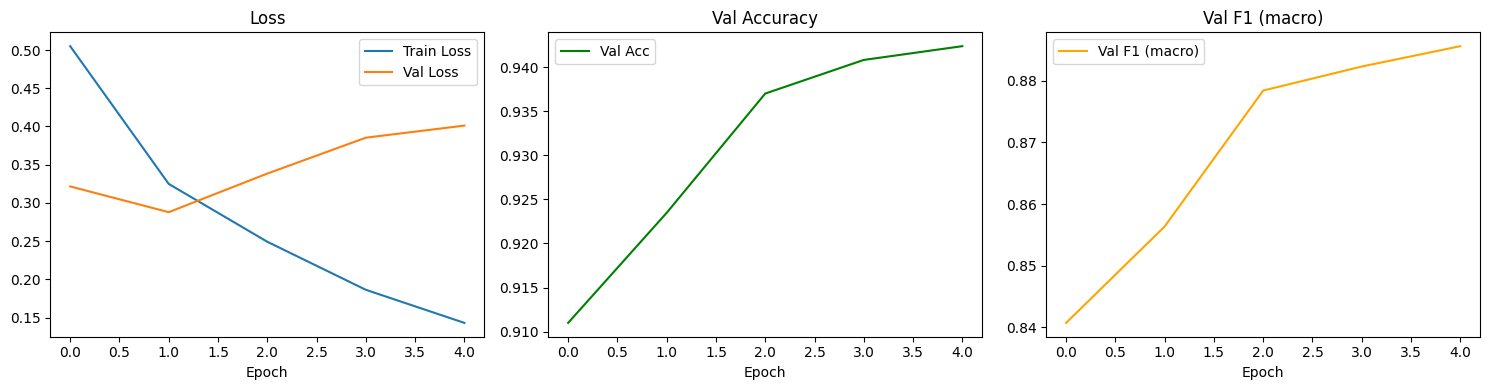

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'],   label='Val Loss')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].set_xlabel('Epoch')

axes[1].plot(history['val_acc'], label='Val Acc', color='green')
axes[1].set_title('Val Accuracy'); axes[1].legend(); axes[1].set_xlabel('Epoch')

axes[2].plot(history['val_f1'], label='Val F1 (macro)', color='orange')
axes[2].set_title('Val F1 (macro)'); axes[2].legend(); axes[2].set_xlabel('Epoch')

plt.tight_layout()
plt.savefig(DATA_PATH + 'training_curves.png', dpi=150)
plt.show()

---
## STEP 10. Test set 최종 평가

Eval :   0%|          | 0/363 [00:00<?, ?it/s]

[STEP 10] Test set 최종 성능
Accuracy     : 0.9412
F1 (macro)   : 0.8892

[클래스별 성능]
              precision    recall  f1-score   support

          부정     0.9312    0.9239    0.9275      1392
          중립     0.7345    0.8142    0.7723       479
          긍정     0.9730    0.9629    0.9679      3931

    accuracy                         0.9412      5802
   macro avg     0.8796    0.9003    0.8892      5802
weighted avg     0.9433    0.9412    0.9421      5802



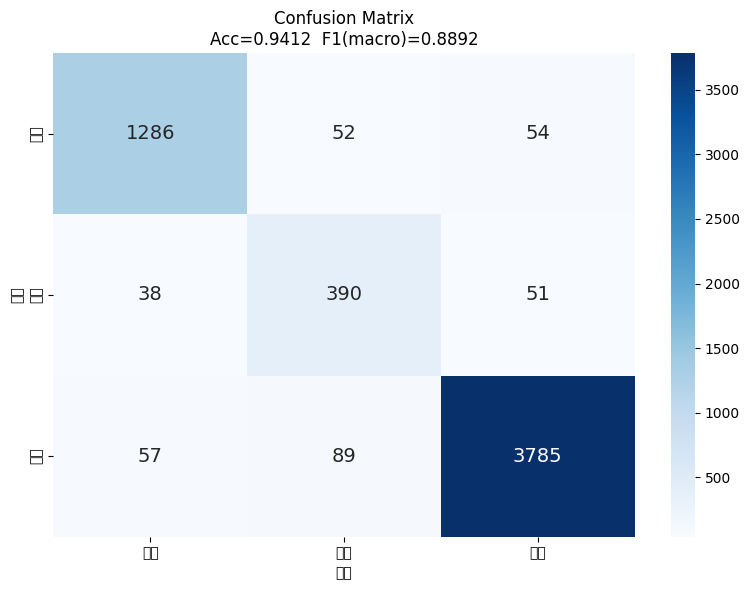

In [ ]:
# Best 모델 로드
model.load_state_dict(torch.load(best_model_path))

test_loss, test_acc, test_f1, test_preds, test_labels = eval_epoch(model, test_loader, criterion, device)

print('=' * 60)
print('[STEP 10] Test set 최종 성능')
print('=' * 60)
print(f'Accuracy     : {test_acc:.4f}')
print(f'F1 (macro)   : {test_f1:.4f}')
print()
print('[클래스별 성능]')
print(classification_report(test_labels, test_preds,
                              target_names=['부정','중립','긍정'], digits=4))

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['부정','중립','긍정'],
            yticklabels=['부정','중립','긍정'],
            annot_kws={'size': 14})
plt.xlabel('예측'); plt.ylabel('실제')
plt.title(f'Confusion Matrix\nAcc={test_acc:.4f}  F1(macro)={test_f1:.4f}')
plt.tight_layout()
plt.savefig(DATA_PATH + 'confusion_matrix_final.png', dpi=150)
plt.show()

---
## STEP 11. 단일 예측 테스트 (추론 함수)

In [ ]:
def predict(text: str, aspect: str, model, tokenizer, device, max_len=192) -> dict:
    """
    리뷰 텍스트 + aspect를 넣으면 감정 예측 결과를 반환합니다.
    token_type_ids 포함 버전.
    """
    model.eval()
    enc = tokenizer(
        text, aspect,
        add_special_tokens=True,
        max_length=max_len,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_token_type_ids=True,   # ← 추가
        return_tensors='pt'
    )

    with torch.no_grad():
        logits = model(
            input_ids=enc['input_ids'].to(device),
            attention_mask=enc['attention_mask'].to(device),
            token_type_ids=enc['token_type_ids'].to(device)   # ← 필수
        )

    probs      = torch.softmax(logits, dim=1)[0].tolist()
    pred_label = int(torch.argmax(logits, dim=1).item())

    return {
        'text'      : text,
        'aspect'    : aspect,
        'prediction': label_map[pred_label],
        'label_id'  : pred_label,
        'prob_neg'  : round(probs[0], 4),
        'prob_neu'  : round(probs[1], 4),
        'prob_pos'  : round(probs[2], 4),
    }


# 예측 테스트
test_cases = [
    ('가격대비 너무 좋아요! 보습도 잘 되고 향기도 은은해요.',         '보습력/수분감'),
    ('가격은 좀 비싸지만 효과는 확실히 좋네요.',                      '가격'),
    ('흡수가 너무 느려서 아침에 쓰기가 불편해요.',                    '흡수력'),
    ('자극은 없는데 효과도 잘 모르겠어요. 그냥 무난한 것 같아요.',    '기능/효과'),
]

print('=' * 60)
print('[STEP 11] 단일 예측 테스트')
print('=' * 60)
for text, aspect in test_cases:
    result = predict(text, aspect, model, tokenizer, device)
    print(f'텍스트 : {result["text"]}')
    print(f'Aspect : {result["aspect"]}')
    print(f'예측   : {result["prediction"]}  (부정={result["prob_neg"]:.3f} / 중립={result["prob_neu"]:.3f} / 긍정={result["prob_pos"]:.3f})')
    print('-' * 50)

[STEP 11] 단일 예측 테스트
텍스트 : 가격대비 너무 좋아요! 보습도 잘 되고 향기도 은은해요.
Aspect : 보습력/수분감
예측   : 긍정  (부정=0.000 / 중립=0.000 / 긍정=1.000)
--------------------------------------------------
텍스트 : 가격은 좀 비싸지만 효과는 확실히 좋네요.
Aspect : 가격
예측   : 부정  (부정=1.000 / 중립=0.000 / 긍정=0.000)
--------------------------------------------------
텍스트 : 흡수가 너무 느려서 아침에 쓰기가 불편해요.
Aspect : 흡수력
예측   : 부정  (부정=1.000 / 중립=0.000 / 긍정=0.000)
--------------------------------------------------
텍스트 : 자극은 없는데 효과도 잘 모르겠어요. 그냥 무난한 것 같아요.
Aspect : 기능/효과
예측   : 중립  (부정=0.012 / 중립=0.986 / 긍정=0.002)
--------------------------------------------------


In [ ]:
# 같은 문장, 다른 Aspect → 결과가 달라지는지 확인
sentence = '가격은 좀 비싸지만 효과는 확실히 좋네요.'

for aspect in ['가격', '기능/효과']:
    result = predict(sentence, aspect, model, tokenizer, device)
    print(f'Aspect: {aspect:10s} → 예측: {result["prediction"]}  '
          f'(부정={result["prob_neg"]:.3f} / 중립={result["prob_neu"]:.3f} / 긍정={result["prob_pos"]:.3f})')

Aspect: 가격         → 예측: 부정  (부정=1.000 / 중립=0.000 / 긍정=0.000)
Aspect: 기능/효과      → 예측: 긍정  (부정=0.000 / 중립=0.000 / 긍정=0.999)
